# §9 Robustness and Credibility (Stage S9)

§7 reached its verdicts on one set of folds, one label definition, one imputation rule and one
regularisation strength. This section asks how much of that is **procedure** and how much is **data**:

* **controls** – does the evaluation produce AUC 0.5 when there is nothing to find (label permutation,
  pure-noise feature), and does it find a signal of known size (positive control)?
* **stability** – does the headline comparison S − M1 keep its verdict under other CV seeds, 16
  pre-specified analysis variations, a 60-specification curve, survey-cluster folds and a
  missing-not-at-random scenario for HbA1c?
* **external validity** – do our population numbers line up with the published NCHS Data Brief 516?
* **leak hunt (loop L3)** – could any admissible feature be a disguised label?
* **hold-out** – the 20 % hold-out is evaluated **once**, only after the `exp-freeze` tag.

All work before section 11 uses the training part only (4,584 rows). Headline comparison throughout:
ΔAUC(S − M1), the "minimal vs systematic" contrast of hypothesis H2b(a) (locked rule: *supported* =
equivalence within ±0.01; §7 verdict *inconclusive*).

Contents: 1 reference · 2 controls · 3 seeds · 4 sensitivity table · 5 specification curve · 6 survey-cluster
CV · 7 missing HbA1c (IPW, delta) · 8 external validity · 9 leak hunt · 10 pre-hold-out summary ·
11 one-shot hold-out · 12 storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as sv, robustness as RB
from src.robustness import Spec

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("PYTHONWARNINGS", "ignore")
OUT = C.RESULTS_DIR / "S9"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(16, max(1, (os.cpu_count() or 2) - 2))
T_START = time.time()
S9 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm": C.N_PERM,
      "n_boot_coef": C.N_BOOT_COEF}
OI = C.OKABE_ITO
S7m = R.load_section("S7")
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, permutations = {C.N_PERM}, {N_JOBS} workers")

mode FAST: 5x2 CV, B = 100, permutations = 20, 16 workers


## 1 Reference comparison
**Why.** Every robustness check varies one thing against a fixed reference, so the reference must be
exactly the §7 run: same training part, same stored folds, frozen C0, same comparison engine
(`robustness.compare` mirrors the §7 engine: Nadeau–Bengio corrected t and paired bootstrap, wider interval on
E-ALL; bootstrap only on E-SCREEN).

In [2]:
ctx = RB.load_context()
RUNS = {}                                              # cache: (Spec, folds hash) -> OOF frame
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
assert ctx.folds.hash == S7m["splits"]["folds_hash"] or not C.IS_FINAL, "FINAL run must use the S7 folds"
assert hold["sha256_test_seqn"] == S7m["splits"]["holdout_sha256"]
print(f"training part {ctx.n:,} rows, {ctx.y.sum()} L_comb positives; E-SCREEN {ctx.esc.sum():,} rows, "
      f"{ctx.y_esc[ctx.esc].sum()} positives; folds {len(ctx.folds)} ({ctx.folds.path.name}, hash {ctx.folds.hash[:12]}...)")
print(f"frozen C0 = {ctx.C0}; hold-out {len(ctx.test_idx):,} rows (SHA-256 {hold['sha256_test_seqn'][:16]}...) not read here")

def pair(spec_a, spec_b, folds=None, *, tag, label="L_comb", rows=None, use_t=True, w=None):
    """Run two specs (cached) and compare A - B on E-ALL (label) and E-SCREEN; returns two rows."""
    folds = ctx.folds if folds is None else folds
    oof = RB.run_many(ctx, {"a": spec_a, "b": spec_b}, folds, n_jobs=N_JOBS, cache=RUNS)
    f, mask = RB.spec_folds(ctx, spec_a, folds)
    _, mb = RB.spec_folds(ctx, spec_b, folds)
    assert (mask == mb).all(), "paired specs must use the same rows"
    lab = ctx.labels[label].to_numpy()[mask].astype(int)
    esc, y_esc = ctx.esc[mask], ctx.y_esc[mask]
    ww = None if w is None else w[mask]
    out = []
    for pop, yy, m, t in (("E-ALL", lab, None, use_t), ("E-SCREEN", y_esc, esc, False)):
        r = RB.compare(oof["a"], oof["b"], yy, f, mask=m, w=ww, use_t=t, seed_=RB.seed(tag, pop))
        out.append(dict(tag=tag, pop=pop, **r))
    return out

ref = pair(Spec("S"), Spec("M1"), tag="reference")
ref_df = pd.DataFrame(ref)
print(ref_df[["pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b"]].round(4).to_string(index=False))
s7_ref = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "H2b" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
if C.IS_FINAL:   # identical folds, model and engine -> identical numbers
    assert abs(ref[0]["est"] - s7_ref["est"]) < 5e-5 and abs(ref[0]["hi"] - s7_ref["hi"]) < 5e-5, (ref[0]["est"], s7_ref)
print(f"S7 stored (FINAL): {s7_ref['est']:+.4f} [{s7_ref['lo']:+.4f}, {s7_ref['hi']:+.4f}] -> {s7_ref['verdict']}")
S9["reference"] = {r["pop"]: {k: r[k] for k in ("auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b")} for r in ref}

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives; folds 10 (folds_FAST.npz, hash eb0f2b5f07f6...)
frozen C0 = 0.1; hold-out 1,146 rows (SHA-256 616fd0590bec7b92...) not read here


     pop  auc_a  auc_b    est      lo     hi  interval    mdd          h2b
   E-ALL 0.8351 0.8277 0.0074  0.0001 0.0142 bootstrap 0.0093 inconclusive
E-SCREEN 0.7791 0.7715 0.0076 -0.0085 0.0250 bootstrap 0.0239 inconclusive
S7 stored (FINAL): +0.0079 [+0.0000, +0.0158] -> inconclusive


**So what.** In FINAL mode the reference reproduces §7 to the fourth decimal (asserted): S is better than M1
by about +0.008 AUC on E-ALL, but the interval runs from about 0 to about +0.016 – it neither excludes a
0.01 difference nor sits inside ±0.01, so H2b(a) is *inconclusive*. The question for every check below is
whether this verdict – not the point estimate – survives.

## 2 Negative and positive controls
### 2.1 Label permutation
**Why.** If the evaluation procedure leaked label information (preprocessing fitted on test rows, weights
derived from the label, a fold bug), a model trained on *permuted* labels would still score above 0.5. Each
permutation shuffles the training label of the whole training part, refits on the same folds and records
the mean per-fold AUC (`evalkit.permutation_auc`, Ojala & Garriga 2010). Acceptance: null mean in
[0.495, 0.505]. Features stay attached to their rows, so this test **cannot** detect feature leakage – that
is the job of the leak hunt (section 9).

arm  observed  null_mean  null_sd  null_min  null_max  p_value  n_perm  in_band
 M1    0.8270     0.5001   0.0146    0.4806    0.5349   0.0476      20     True
  S    0.8345     0.5007   0.0124    0.4700    0.5180   0.0476      20     True
420 fits in 42 s


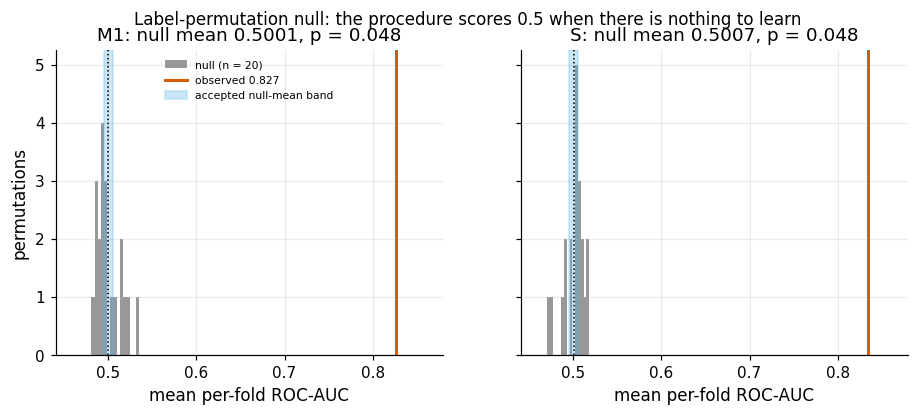

In [3]:
t0 = time.time()
PERM = {arm: RB.permutation_null(ctx, Spec(arm), n_perm=C.N_PERM, seed_=RB.seed("perm", arm), n_jobs=N_JOBS)
        for arm in RB.ADMISSIBLE_ARMS}
perm_tab = pd.DataFrame([dict(arm=a, observed=d["observed"], null_mean=d["null_mean"], null_sd=d["null_sd"],
                              null_min=d["null"].min(), null_max=d["null"].max(), p_value=d["p_value"], n_perm=d["n_perm"],
                              in_band=RB.PERM_NULL_BAND[0] <= d["null_mean"] <= RB.PERM_NULL_BAND[1])
                         for a, d in PERM.items()])
perm_tab.to_csv(OUT / "permutation.csv", index=False)
print(perm_tab.round(4).to_string(index=False))
print(f"{sum(len(ctx.folds) * (d['n_perm'] + 1) for d in PERM.values())} fits in {time.time() - t0:.0f} s")
assert perm_tab["in_band"].all(), "permutation null mean outside [0.495, 0.505]: procedural leakage suspected"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (arm, d) in zip(axes, PERM.items()):
    ax.hist(d["null"], bins=15, color=OI["grey"], alpha=0.8, label=f"null (n = {d['n_perm']})")
    ax.axvline(d["observed"], color=OI["vermillion"], lw=2, label=f"observed {d['observed']:.3f}")
    ax.axvspan(*RB.PERM_NULL_BAND, color=OI["sky"], alpha=0.3, label="accepted null-mean band")
    ax.axvline(d["null_mean"], color="k", ls=":", lw=1)
    ax.set(title=f"{arm}: null mean {d['null_mean']:.4f}, p = {d['p_value']:.3f}", xlabel="mean per-fold ROC-AUC")
    ax.set_xlim(0.44, 0.88)
axes[0].set_ylabel("permutations")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Label-permutation null: the procedure scores 0.5 when there is nothing to learn", fontsize=11)
plots.savefig(fig, "S9_permutation_null", caption="F9-1. Mean per-fold ROC-AUC of M1 and S refitted on permuted training labels "
              f"({C.N_PERM} permutations, same folds; grey) against the observed value (red). Blue band = acceptance range "
              "[0.495, 0.505] for the null mean; dotted line = null mean. Training part, Tier 1, E-ALL.")
plt.show()
S9["permutation"] = perm_tab.set_index("arm").to_dict("index")

**So what.** Both null distributions are centred on 0.5 (means printed above, inside the acceptance band) and
no permutation comes near the observed AUC (p is the smallest value attainable with this number of
permutations). The cross-validation, the in-fold preprocessing and the survey and class weights do not leak
label information into the score. This is a statement about the *procedure* only.

### 2.2 Pure-noise feature
**Why.** A feature that is pure noise must look like noise to the model: an N(0, 1) column appended to the raw
frame should get a coefficient whose bootstrap interval covers 0, should not change the AUC, and should never
be chosen by the depth-3 tree. A model that "finds" signal in noise overfits; a pipeline that turns noise into
signal leaks.

In [4]:
rng = np.random.default_rng(RB.seed("noise"))
ctx.extras["noise_n01"] = rng.standard_normal(ctx.n)
noise_rows, NOISE_CB = [], {}
for arm in RB.ADMISSIBLE_ARMS:
    sp = Spec(arm, extra=("noise_n01",))
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    cb = ek.coef_bootstrap(lambda sp=sp: RB.make_pipe(sp, ctx.C0), X_, y_.astype(int), n_boot=C.N_BOOT_COEF,
                           seed=RB.seed("noise-coef", arm), fit_params=None if sw_ is None else {"model__sample_weight": sw_},
                           n_jobs=N_JOBS)
    NOISE_CB[arm] = cb
    s = cb.summary.loc["noise_n01"]
    sdz = float(RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)["noise_n01"].std())   # per-SD scale of the design column
    cmp_ = pair(sp, Spec(arm), tag=f"noise-{arm}")
    tr_ = RB.tree_features_used(ctx, Spec(arm, model="tree", extra=("noise_n01",)), ctx.folds, "noise_n01")
    tr4 = RB.tree_features_used(ctx, Spec(arm, model="tree", depth=4, extra=("noise_n01",)), ctx.folds, "noise_n01")
    zt = (cb.summary["coef"] / cb.summary["sd"]).abs()                                # bootstrap |z| for a scale-free rank
    rank = int(zt.rank(ascending=False)["noise_n01"])
    noise_rows.append(dict(arm=arm, coef_per_sd=s["coef"] * sdz, q_low=s["q_low"] * sdz, q_high=s["q_high"] * sdz,
                           ci_covers_0=bool(s["q_low"] <= 0 <= s["q_high"]), abs_z_rank=f"{rank}/{len(cb.summary)}", abs_z=float(zt["noise_n01"]),
                           dAUC_eall=cmp_[0]["est"], dAUC_eall_lo=cmp_[0]["lo"], dAUC_eall_hi=cmp_[0]["hi"],
                           dAUC_eall_verdict=RB.equivalence_verdict(cmp_[0]["lo"], cmp_[0]["hi"]),
                           tree3_uses=int(tr_["uses_feature"].sum()), tree4_uses=int(tr4["uses_feature"].sum()),
                           n_trees=len(tr_)))
noise_tab = pd.DataFrame(noise_rows)
noise_tab.to_csv(OUT / "noise_feature.csv", index=False)
print(noise_tab.round(4).to_string(index=False))
assert noise_tab["ci_covers_0"].all() and (noise_tab["tree3_uses"] == 0).all()
S9["noise_feature"] = noise_tab.set_index("arm").to_dict("index")

arm  coef_per_sd   q_low  q_high  ci_covers_0 abs_z_rank  abs_z  dAUC_eall  dAUC_eall_lo  dAUC_eall_hi dAUC_eall_verdict  tree3_uses  tree4_uses  n_trees
 M1       0.0118 -0.0620  0.1030         True      43/47 0.2664     0.0001       -0.0007        0.0009         supported           0           0       11
  S       0.0482 -0.0736  0.1486         True      31/43 0.7598     0.0000       -0.0006        0.0007         supported           0           1       11


**So what.** In both admissible arms the noise coefficient ranks near the bottom by |coefficient / bootstrap SD|,
its bootstrap interval covers 0, adding the column leaves the AUC unchanged within ±0.01, and none of the
depth-3 trees (one per training fold plus the full fit) splits on it. The depth-4 count is reported for
completeness: a deeper tree has more chances to chase noise, and that is one reason the protocol caps the
tree at depth 3.

### 2.3 Positive control
**Why.** Negative controls show the procedure is not too optimistic; a positive control shows it is not blind.
A synthetic column z = d·y + N(0, 1), with d = √2·Φ⁻¹(0.60), has a known population AUC of 0.60 – a weak but
real signal, independent of every other feature given the label. The procedure must (i) recover its AUC and
(ii) detect the increment when z is added to M1 and S (paired ΔAUC interval excluding 0).

In [5]:
ctx.extras["pos_control"] = RB.signal_feature(ctx.y, RB.POS_CONTROL_AUC, seed_=RB.seed("positive-control"))
z_auc = RB.auc_ci(ctx.y, ctx.extras["pos_control"].to_numpy(), seed_=RB.seed("z-auc"))
print(f"single-feature AUC of z: {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}] (design value {RB.POS_CONTROL_AUC:.2f})")
pos_rows = []
for arm in RB.ADMISSIBLE_ARMS:
    for r in pair(Spec(arm, extra=("pos_control",)), Spec(arm), tag=f"pos-{arm}"):
        pos_rows.append(dict(arm=arm, pop=r["pop"], auc_without=r["auc_b"], auc_with=r["auc_a"], est=r["est"], lo=r["lo"],
                             hi=r["hi"], interval=r["interval"], detected=bool(r["lo"] > 0)))
pos_tab = pd.DataFrame(pos_rows)
pos_tab.to_csv(OUT / "positive_control.csv", index=False)
print(pos_tab.round(4).to_string(index=False))
assert z_auc[1] <= RB.POS_CONTROL_AUC <= z_auc[2], "positive-control AUC not recovered"
assert pos_tab.loc[pos_tab["pop"] == "E-ALL", "detected"].all(), "positive control not detected on E-ALL"
S9["positive_control"] = dict(z_auc=z_auc, rows=pos_tab.to_dict("records"))

single-feature AUC of z: 0.588 [0.569, 0.608] (design value 0.60)


arm      pop  auc_without  auc_with    est      lo     hi    interval  detected
 M1    E-ALL       0.8277    0.8341 0.0062  0.0011 0.0114 corrected_t      True
 M1 E-SCREEN       0.7715    0.7835 0.0120 -0.0000 0.0228   bootstrap     False
  S    E-ALL       0.8351    0.8412 0.0059  0.0015 0.0104 corrected_t      True
  S E-SCREEN       0.7791    0.7922 0.0132  0.0032 0.0240   bootstrap      True


**So what.** The column's AUC is recovered (its interval contains the design value 0.60), and adding it raises
the E-ALL AUC of both arms with an interval that excludes 0, so a signal of this size would not be missed. The
increment is much smaller than 0.10 because the remaining features already rank most cases correctly – which
also calibrates expectations: a new risk factor with a univariate AUC of 0.60 buys only a few thousandths of
AUC on top of age, adiposity and blood pressure.